# CCA_001 / CCA_002 / CCA_003: overview of the RTD fits on AZA_001

All fits of the AZA_001 rig data (Alex Zirn, 2025-06-13) in `Runs/`, side by side, plus Alex's original kernels
(`AZA_001/Runs/Run_2025-06-30_144137.npy`) for reference. The notebook picks up the newest run of each
(script, tracers) combination; rerun it after a new run.

| script | rows fitted as | tracers |
|---|---|---|
| CCA_001 | absolute mole fractions | Ar, Ar+He |
| CCA_002 | deviation from the level before the step (same model, baseline removed from the loss) | Ar, He, Ar+He |
| CCA_003 | as CCA_002, every kernel starts from a smooth bump sin²(πt/T) (0 at t = 0, mean at T/2) instead of a spike | Ar, He, Ar+He |

Every kernel set is evaluated on every tracer and edge, so each fit is also scored on the data it was not fitted on.
Shape metric: the unit step response of the section's chain (the kernels the section was fitted with, the others at
direct response, through nRTD) against the mean F of the measured rows; F = (x − x_before) / (x_after − x_before).
The kernel integral ΣE·dt is reported separately: applied to an absolute signal, a deviation of ΣE·dt from 1 adds
(ΣE·dt − 1)·x_before/Δ to F, which matters for He (x_before/Δ ≈ 3–8) and not for Ar from zero.

This notebook does not choose a fit. Section 7 lists the trade-offs.

In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

REPO = Path("/home/hannes/Documents/PythonCode/nRTD")
sys.path.insert(0, str(REPO / "lib"))
from nRTD.rtd_net import RTDNet

torch.set_default_dtype(torch.float64)
pd.set_option("display.width", 200)
RUNS = REPO / "Experiments" / "CCA" / "Runs"
SECTIONS = ("cap", "upstream", "total")
UP, DOWN, CAP = 0, 1, 2
CHAIN = {"cap": (CAP,), "upstream": (UP, CAP), "total": (UP, DOWN, CAP)}
KERNEL_TIMES = [(0.0, 20.0), (0.0, 45.0), (0.0, 20.0)]
DT = 0.25

# newest run per (script, tracers)
found = {}
for f in sorted(RUNS.glob("CCA_00[123]_*_20??-??-??_??????.npy")):
    m = re.match(r"(CCA_00[123])_(Ar|He|ArHe)_(\d{4}-\d{2}-\d{2}_\d{6})\.npy", f.name)
    if m:
        found[f"{m[1]} {m[2]}"] = f
runs = {k: np.load(f, allow_pickle=True).item() for k, f in sorted(found.items())}
names = {k: f.stem for k, f in found.items()}
alex = np.load(
    REPO / "Experiments" / "AZA_001" / "Runs" / "Run_2025-06-30_144137.npy",
    allow_pickle=True,
).item()
kernels = {k: r["Es"] for k, r in runs.items()} | {"Alex 2025-06-30": alex["Es"]}
missing = [
    k
    for k in (
        "CCA_001 Ar",
        "CCA_001 ArHe",
        "CCA_002 Ar",
        "CCA_002 He",
        "CCA_002 ArHe",
        "CCA_003 Ar",
        "CCA_003 He",
        "CCA_003 ArHe",
    )
    if k not in runs
]

rows = []
for k, r in runs.items():
    s = r["settings"]
    rows.append(
        {
            "fit": k,
            "run": names[k],
            "tracers": s["tracers"],
            "rows": s.get("rows", "absolute mole fractions"),
            "epochs/section": s["epochs_per_section"],
            "seed": s["seed"],
            "lr": s["lr"],
            "wall [s]": round(sum(s["wall_s"].values())),
            "nRTD": r["versions"]["nRTD"][:8],
        }
    )
print("missing runs:", missing or "none")
pd.DataFrame(rows)

missing runs: none


,fit,run,tracers,rows,epochs/section,seed,lr,wall [s],nRTD
0,CCA_001 Ar,CCA_001_Ar_2026-10-30_152309,Ar,absolute mole fractions,20000,0,0.004,1097,31b36cea
1,CCA_001 ArHe,CCA_001_ArHe_2026-10-30_152347,Ar+He,absolute mole fractions,20000,0,0.004,1389,31b36cea
2,CCA_002 Ar,CCA_002_Ar_2026-10-30_162016,Ar,deviation from level before the step,20000,0,0.004,153,31b36cea
3,CCA_002 ArHe,CCA_002_ArHe_2026-10-30_162842,Ar+He,deviation from level before the step,20000,0,0.004,272,31b36cea
4,CCA_002 He,CCA_002_He_2026-10-30_162256,He,deviation from level before the step,20000,0,0.004,146,31b36cea
5,CCA_003 Ar,CCA_003_Ar_2026-10-31_135249,Ar,deviation from level before the step,20000,0,0.004,147,31b36cea
6,CCA_003 ArHe,CCA_003_ArHe_2026-10-31_135759,Ar+He,deviation from level before the step,20000,0,0.004,223,31b36cea
7,CCA_003 He,CCA_003_He_2026-10-31_135523,He,deviation from level before the step,20000,0,0.004,148,31b36cea


## 1. Same data in all runs?

The reference data set is the run that holds both tracers (CCA_001 Ar+He: all 48 / 20 rows). Every other run's rows (original levels) must equal the matching rows there.

In [2]:
ref_key = "CCA_001 ArHe"
ref = runs[ref_key]
ROWSEL = {"Ar": slice(0, None, 2), "He": slice(1, None, 2), "ArHe": slice(None)}
rows = []
for k, r in runs.items():
    sel = ROWSEL[k.split()[1]]
    for s in SECTIONS:
        rows.append(
            {
                "fit": k,
                "section": s,
                "max |Δ x_out|": np.abs(r[f"x_out {s}"] - ref[f"x_out {s}"][sel]).max(),
                "max |Δ x_in|": np.abs(r[f"x_in {s}"] - ref[f"x_in {s}"][sel]).max(),
                "max |Δ t_out|": np.abs(r[f"t_out {s}"] - ref[f"t_out {s}"][sel]).max(),
            }
        )
pd.DataFrame(rows).pivot_table(index="fit", columns="section", values="max |Δ x_out|")

section,cap,total,upstream
fit,,,
CCA_001 Ar,0.000000e+00,0.000000e+00,0.000000e+00
CCA_001 ArHe,0.000000e+00,0.000000e+00,0.000000e+00
CCA_002 Ar,3.469447e-18,3.469447e-18,6.938894e-18
CCA_002 ArHe,3.469447e-18,3.469447e-18,6.938894e-18
CCA_002 He,0.000000e+00,0.000000e+00,0.000000e+00
CCA_003 Ar,3.469447e-18,3.469447e-18,6.938894e-18
CCA_003 ArHe,3.469447e-18,3.469447e-18,6.938894e-18
CCA_003 He,0.000000e+00,0.000000e+00,0.000000e+00


## 2. Measured data per group

Groups in the reference rows (the data modules stack Ar, He per window; Ar rises in even windows, He falls in them). Mean F per group, its crossing times and the repeat scatter.

In [3]:
GROUPS = {
    "Ar rise": slice(0, None, 4),
    "Ar fall": slice(2, None, 4),
    "He rise": slice(3, None, 4),
    "He fall": slice(1, None, 4),
}
T_STEP = 1.0  # all CCA windows put the step at 1.0 s


def F_rows(r, s):
    x, y = r[f"x_in {s}"][:, 0], r[f"x_out {s}"][:, 0]
    return (y - x[:, :1]) / (x[:, -1:] - x[:, :1])


def crossings(t, F):
    return {
        f"t{int(l * 100)}": float(t[np.argmax(F > l)] - T_STEP) for l in (0.1, 0.5, 0.9)
    }


data = {}
rows = []
for s in SECTIONS:
    t, F = ref[f"t_out {s}"][0], F_rows(ref, s)
    x = ref[f"x_in {s}"][:, 0]
    for g, sl in GROUPS.items():
        data[s, g] = F[sl].mean(axis=0)
        rows.append(
            {
                "section": s,
                "group": g,
                "rows": F[sl].shape[0],
                **crossings(t, data[s, g]),
                "repeat std (max)": F[sl].std(axis=0).max(),
                "x_before / Δ": abs(
                    x[sl, 0].mean() / (x[sl, -1].mean() - x[sl, 0].mean())
                ),
            }
        )
print("crossing times in s after the step")
pd.DataFrame(rows).style.format(precision=3)

crossing times in s after the step


,section,group,rows,t10,t50,t90,repeat std (max),x_before / Δ
0,cap,Ar rise,5,0.750,1.000,4.000,0.048,0.000
1,cap,Ar fall,5,0.750,1.250,4.500,0.137,1.000
2,cap,He rise,5,0.750,1.250,3.750,0.140,3.206
3,cap,He fall,5,0.750,1.250,3.500,0.068,4.327
4,upstream,Ar rise,12,1.250,1.750,5.500,0.010,0.001
5,upstream,Ar fall,12,1.250,1.750,6.250,0.012,1.002
6,upstream,He rise,12,1.250,1.750,6.500,0.044,7.272
7,upstream,He fall,12,1.250,1.750,6.250,0.040,8.212
8,total,Ar rise,12,22.500,24.500,32.250,0.009,0.001
9,total,Ar fall,12,22.750,24.750,30.750,0.013,1.001


## 3. Fit quality: every kernel set on every group

max |ΔF| / RMS ΔF of the unit step response against the mean data of each group, over the 120 s window, and the t50 difference (fit − data, s; 0.25 s grid).

In [4]:
def step_response(E, s, t):
    net = RTDNet(kernel_sizes=[e.size for e in E], kernel_times=KERNEL_TIMES)
    for i, conv in enumerate(net.conv_layers):
        if i in CHAIN[s]:
            conv.E = torch.tensor(np.asarray(E[i]))
        else:
            conv.set_to_direct_response()
    t_in = torch.tensor(ref[f"t_in {s}"][:1])
    x = (t_in >= T_STEP).double()[:, None, :]
    with torch.no_grad():
        y, _ = net(x, t_in)
    return y[0, 0].numpy()


resp = {
    (k, s): step_response(E, s, ref[f"t_out {s}"][0])
    for k, E in kernels.items()
    for s in SECTIONS
}
rows = []
for (k, s), S in resp.items():
    t = ref[f"t_out {s}"][0]
    for g in GROUPS:
        d = S - data[s, g]
        rows.append(
            {
                "fit": k,
                "section": s,
                "group": g,
                "max": np.abs(d).max(),
                "rms": np.sqrt(np.mean(d**2)),
                "Δt50": crossings(t, S)["t50"] - crossings(t, data[s, g])["t50"],
            }
        )
quality = pd.DataFrame(rows)
for metric in ("max", "rms"):
    display(
        quality.pivot_table(
            index=["section", "group"], columns="fit", values=metric, sort=False
        )
        .style.format("{:.3f}" if metric == "max" else "{:.4f}")
        .background_gradient(axis=None, cmap="Reds")
        .set_caption(f"{metric} |ΔF|")
    )

In [5]:
quality.pivot_table(
    index=["section", "group"], columns="fit", values="Δt50", sort=False
).style.format("{:+.2f}").set_caption("t50 fit − t50 data [s]")

## 4. Data and step responses

Per section: mean data of the four groups (thin) and the step response of each fit (thick). Bottom row: fit − mean data, for the groups each fit was fitted on (solid) and for the other tracer (dotted).

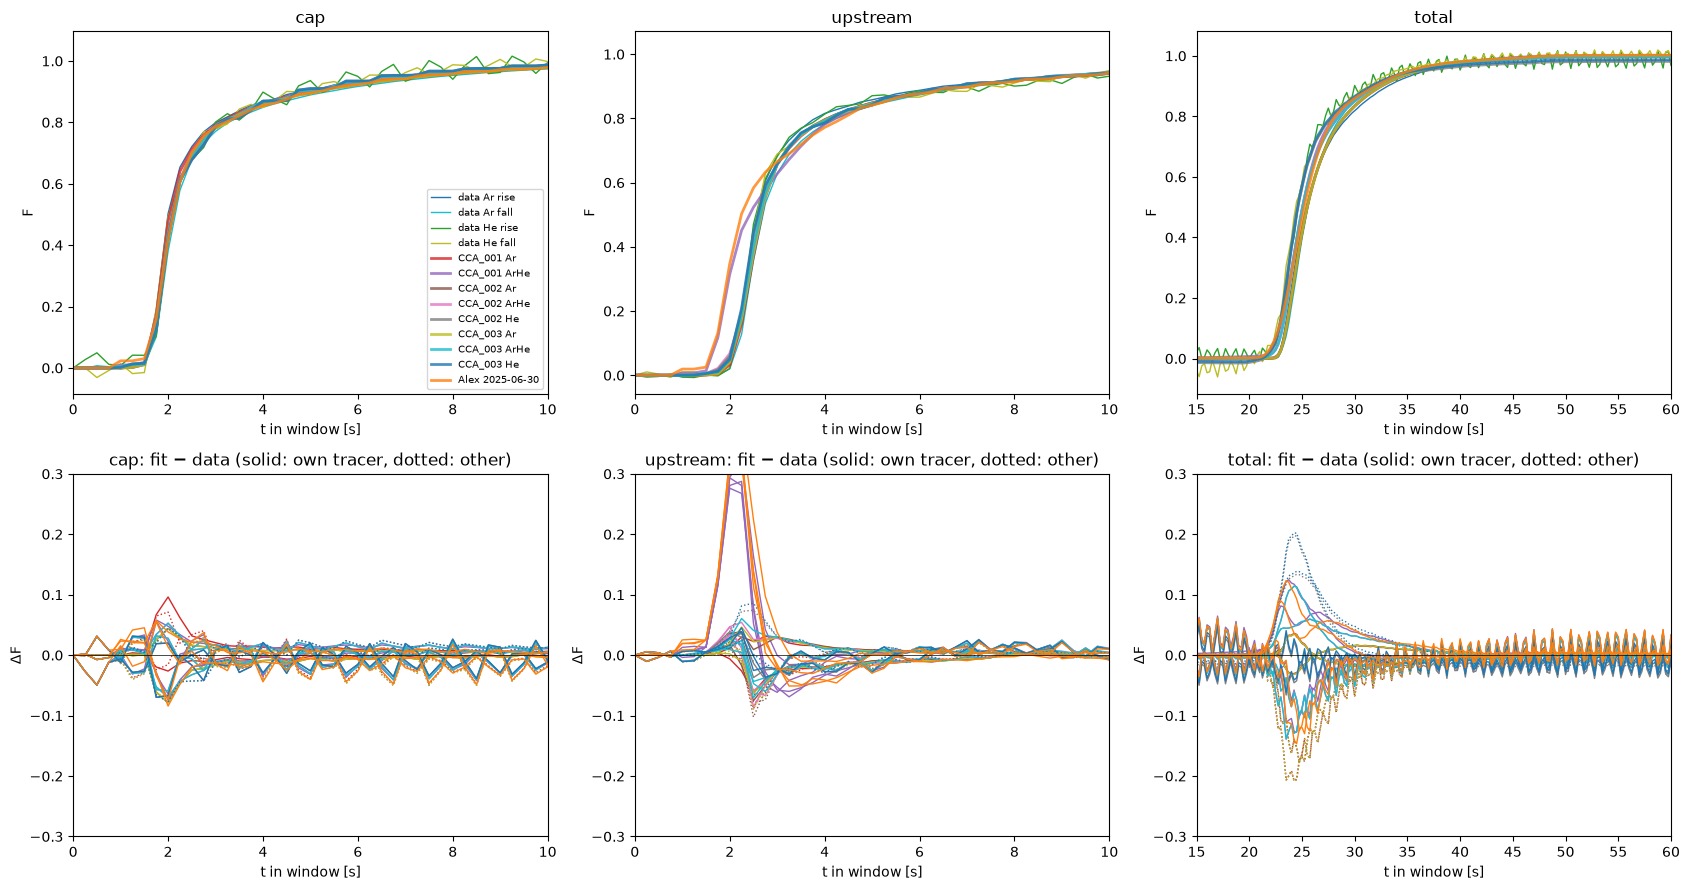

In [6]:
XLIM = {"cap": (0, 10), "upstream": (0, 10), "total": (15, 60)}
GCOL = {"Ar rise": "C0", "Ar fall": "C9", "He rise": "C2", "He fall": "C8"}
fits = [k for k in kernels]
FCOL = {k: f"C{i + 3}" for i, k in enumerate(fits)}
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for j, s in enumerate(SECTIONS):
    t = ref[f"t_out {s}"][0]
    for g in GROUPS:
        ax[0, j].plot(t, data[s, g], c=GCOL[g], lw=1, label=f"data {g}")
    for k in fits:
        ax[0, j].plot(t, resp[k, s], c=FCOL[k], lw=2, alpha=0.8, label=k)
        fitted = {"Ar": ("Ar",), "He": ("He",), "ArHe": ("Ar", "He")}.get(
            k.split()[-1], ("Ar", "He")
        )
        for g in GROUPS:
            ax[1, j].plot(
                t,
                resp[k, s] - data[s, g],
                c=FCOL[k],
                lw=1,
                ls="-" if g[:2] in fitted else ":",
            )
    ax[0, j].set(xlim=XLIM[s], title=s, xlabel="t in window [s]", ylabel="F")
    ax[1, j].axhline(0, c="k", lw=0.5)
    ax[1, j].set(
        xlim=XLIM[s],
        ylim=(-0.3, 0.3),
        title=f"{s}: fit − data (solid: own tracer, dotted: other)",
        xlabel="t in window [s]",
        ylabel="ΔF",
    )
ax[0, 0].legend(fontsize=7)
fig.tight_layout()

## 5. Kernels and bed inlet

The bed inlet of the PTK model is step ⊗ E_up (PTK_model_reconciliation LOG F60). E(t=0) > 0 means part of the step passes instantly.

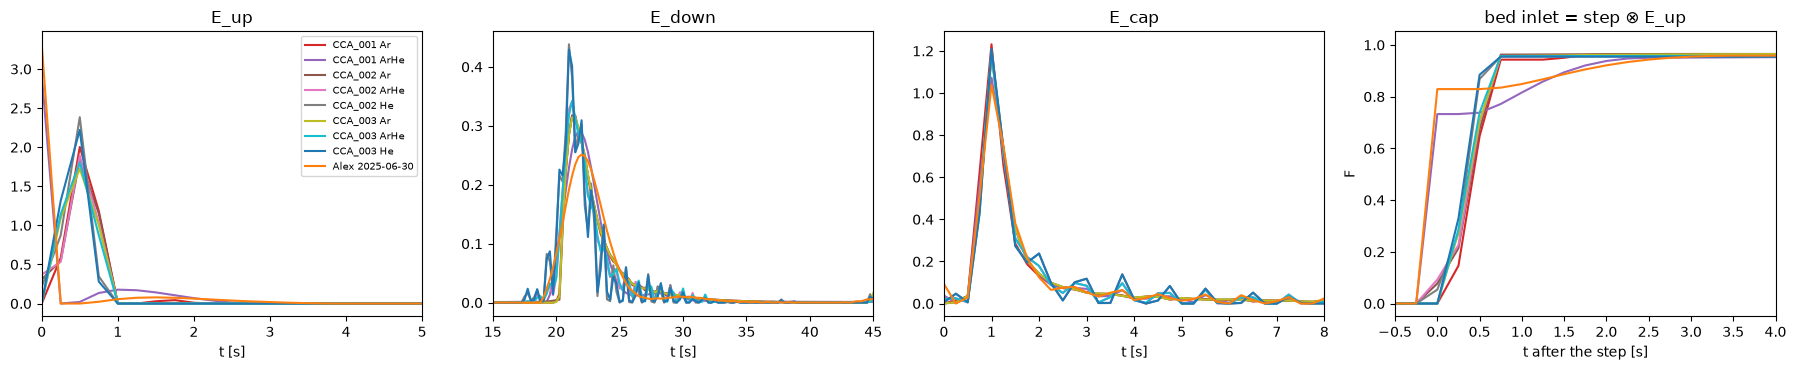

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
rows = []
for k, E in kernels.items():
    for i, (n, xl) in enumerate(
        (("E_up", (0, 5)), ("E_down", (15, 45)), ("E_cap", (0, 8)))
    ):
        t = np.linspace(*KERNEL_TIMES[i], len(E[i]))
        e = np.asarray(E[i])
        ax[i].plot(t, e, c=FCOL[k], label=k)
        ax[i].set(title=n, xlim=xl, xlabel="t [s]")
        rows.append(
            {
                "fit": k,
                "kernel": n,
                "E(0) [1/s]": e[0],
                "ΣE·dt": e.sum() * DT,
                "mean t [s]": (t * e).sum() / e.sum(),
                "t of max [s]": t[np.argmax(e)],
            }
        )
    t_s = np.arange(0, 35 + DT / 2, DT)
    step = (t_s >= T_STEP).astype(float)
    eu = np.asarray(E[UP])
    bed = (
        np.convolve(np.concatenate((np.zeros(eu.size - 1), step)), eu)[
            eu.size - 1 : eu.size - 1 + step.size
        ]
        * DT
    )
    ax[3].plot(t_s - T_STEP, bed, c=FCOL[k], label=k)
ax[3].set(
    title="bed inlet = step ⊗ E_up",
    xlim=(-0.5, 4),
    xlabel="t after the step [s]",
    ylabel="F",
)
ax[0].legend(fontsize=7)
fig.tight_layout()
kt = pd.DataFrame(rows)
kt.pivot_table(
    index="fit",
    columns="kernel",
    values=["E(0) [1/s]", "ΣE·dt", "mean t [s]"],
    sort=False,
).style.format(precision=3)

## 6. Ar vs He in the total system

The tracers have equal timing in the capillary and upstream sections (section 2). Crossing times in the total system: data per group and the step response of each fit.

In [8]:
t = ref["t_out total"][0]
rows = [{"curve": f"data {g}", **crossings(t, data["total", g])} for g in GROUPS]
rows += [{"curve": f"fit {k}", **crossings(t, resp[k, "total"])} for k in kernels]
pd.DataFrame(rows).style.format(precision=2, subset=["t10", "t50", "t90"])

,curve,t10,t50,t90
0,data Ar rise,22.50,24.50,32.25
1,data Ar fall,22.75,24.75,30.75
2,data He rise,22.00,23.75,29.00
3,data He fall,21.75,23.50,30.25
4,fit CCA_001 Ar,22.50,24.50,31.75
5,fit CCA_001 ArHe,22.00,24.25,31.00
6,fit CCA_002 Ar,22.50,24.75,31.50
7,fit CCA_002 ArHe,22.25,24.25,31.25
8,fit CCA_002 He,22.00,23.75,31.00
9,fit CCA_003 Ar,22.75,24.50,31.50


## 7. Trade-offs (facts from the tables above, state 2026-10-31; the choice is Hannes')

Runs included: CCA_001 Ar, CCA_001 Ar+He, CCA_002 Ar, CCA_002 He, CCA_002 Ar+He, CCA_003 Ar, CCA_003 He,
CCA_003 Ar+He, Alex.

**Smooth start (CCA_003 vs CCA_002).** E_cap and E_down end where they ended from the spike start (capillary metrics
identical to three decimals, E_down means 23.145 vs 23.143 s (Ar), 22.641 vs 22.642 s (Ar+He)); with the other kernels
frozen, each stage is a least-squares fit linear in the kernel weights with E ≥ 0, so its optimum does not depend on
the start, and these two stages reached it. E_up did not from the spike: the smooth start removes the residue
(E_up(0) 0.310 → 0.003 s⁻¹ (Ar), 0.370 → 0.000 (Ar+He), 0.215 → 0.000 (He)) at an unchanged mean (0.884 vs 0.883 s,
Ar) and fits the upstream data about as well (max on Ar groups 6.2 vs 7.5 % (Ar), 6.1 vs 5.9 % (Ar+He); He groups
8.9 vs 10.2 % (Ar)). Total system unchanged (Ar 3.5 %, He 20.8 % for the Ar kernels). The Ar/He timing difference in
the total system remains (it is in the data).

**Same data.** All runs hold identical rows (max |Δ x_out| ≤ 7·10⁻¹⁸, section 1).

**Level subtraction, Ar alone (CCA_002 Ar vs CCA_001 Ar).** Little change, as expected for a tracer that starts from
≈ 0: max |ΔF| on the Ar groups 7.9 vs 9.6 % (capillary), 7.5 vs 6.2 % (upstream), 3.5 vs 3.6 % (total). Kernel means
within 0.08 s (E_up 0.88 vs 0.96 s, E_down 23.14 vs 23.11 s, E_cap 2.05 vs 1.99 s). CCA_002 Ar keeps a small start
residue, E_up(0) = 0.31 s⁻¹ (≈ 8 % of the step passes instantly); CCA_001 Ar has none.

**He alone (CCA_002 He).** Fits He in every section: max on the He groups 7.0 % (capillary), 4.1 % (upstream), 6.6 %
(total); CCA_001 Ar+He: 6.4 / 29 / 13 %. E_up(0) = 0.215 s⁻¹. Its E_down is spiky, ΣE·dt = 0.980 and E_down(0) =
−0.002 s⁻¹ (nRTD clamps the weights before each step, so the last update can leave small negatives). He data are
noisier (repeat scatter 4–14 % vs ≈ 1 % for Ar outside the capillary).

**Cross-tracer.** Capillary and upstream: either tracer's kernels describe the other within ≈ 10 % (Ar kernels on He
≤ 10.2 %, He kernels on Ar ≤ 7.8 %); the measured t50 are equal there. Total system: He is ≈ 0.75–1.25 s faster
(data t50 23.5–23.75 s vs 24.5–24.75 s after the step). Ar kernels miss He by 18–21 %, He kernels miss Ar by
13–20 %; E_down means 23.14 s (Ar) vs 22.33 s (He). One E_down cannot describe both tracers.

**Absolute fits with He (CCA_001 Ar+He, Alex).** Upstream misses all groups by 28–38 % (E_up spike 2.9 / 3.3 s⁻¹,
73 / 83 % of the step passing instantly); the cause is the He baseline in the loss (CCA_001_compare.ipynb).

**Kernel integral on absolute signals.** All ΣE·dt are within 0.5 % of 1 except CCA_002 He E_down (0.980). Applied to
an absolute signal this adds (ΣE·dt − 1)·x_before/Δ to F: for He in the total system (x_before/Δ ≈ 6–7.5) about −0.12
to −0.15; for Ar rises (x_before ≈ 0) nothing.

**Bed inlet (step ⊗ E_up).** CCA_001 Ar, CCA_002 Ar and CCA_002 He all reach ≈ 0.95 within 0.75 s of the step, with
0 / 8 / 5 % passing instantly; CCA_001 Ar+He and Alex: 73 / 83 % instantly.

**What each choice buys** (no ranking):
- Ar kernels (CCA_001 or CCA_002): best on Ar, the PTK tracer, in every section; He in the total system off by ≈ 20 %.
  CCA_001 Ar has the cleaner E_up (no residue), CCA_002 Ar a small one.
- He kernels (CCA_002 He): best on He; Ar in the total system off by 13–20 %; noisier E_down with ΣE·dt 0.98.
- Ar + He with level subtraction (CCA_002 Ar+He): no upstream failure any more (max 5.9 % on Ar, 8.6 % on He;
  E_up(0) 0.37 s⁻¹, ≈ 9 % instantly). In the total system a compromise between the tracers: Ar 6.0 / 11.4 %
  (rise / fall), He 10.6 / 13.9 %; E_down mean 22.64 s between Ar (23.14 s) and He (22.33 s), ΣE·dt 0.990.
- Tracer-specific E_down (not implemented): would remove the total-system compromise, at the cost of one more kernel.

In [9]:
summary = (
    quality.groupby(["fit", "section"])
    .apply(
        lambda d: pd.Series(
            {
                "max on Ar groups": d[d.group.str.startswith("Ar")]["max"].max(),
                "max on He groups": d[d.group.str.startswith("He")]["max"].max(),
            }
        ),
        include_groups=False,
    )
    .unstack("section")
)
summary.columns = [f"{m}, {sec}" for m, sec in summary.columns]
summary = summary.join(
    kt.pivot_table(index="fit", columns="kernel", values="E(0) [1/s]").add_prefix(
        "E(0) "
    )
)
summary.style.format(precision=3)

,"max on Ar groups, cap","max on Ar groups, total","max on Ar groups, upstream","max on He groups, cap","max on He groups, total","max on He groups, upstream",E(0) E_cap,E(0) E_down,E(0) E_up
fit,,,,,,,,,
Alex 2025-06-30,0.084,0.123,0.376,0.073,0.146,0.339,0.093,0.000,3.317
CCA_001 Ar,0.096,0.036,0.062,0.071,0.207,0.089,0.000,0.000,0.000
CCA_001 ArHe,0.075,0.125,0.324,0.064,0.127,0.293,0.038,0.000,2.930
CCA_002 Ar,0.079,0.035,0.075,0.068,0.208,0.102,0.000,0.001,0.310
CCA_002 ArHe,0.070,0.114,0.059,0.059,0.139,0.086,0.021,-0.000,0.370
CCA_002 He,0.078,0.198,0.074,0.070,0.066,0.041,0.006,-0.002,0.215
CCA_003 Ar,0.079,0.035,0.062,0.068,0.208,0.089,0.001,0.003,0.003
CCA_003 ArHe,0.070,0.114,0.061,0.059,0.139,0.070,0.021,-0.000,0.000
CCA_003 He,0.078,0.202,0.086,0.070,0.061,0.045,0.006,-0.001,0.000
